<a href="https://colab.research.google.com/github/yeugeneu/IAT360-CV-13-Cloud-Type-Classifier/blob/Data-Preprocessing/cloud_type_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files

1. Make sure you download and extract [Roboflow Cloud Computer Vision Model dataset](https://universe.roboflow.com/ip2-kbjz5/cloud-qthye/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true)

2. Rename the folder to 'CloudDataset'

3. Below steps will guide you through converting the original dataset to the folder hierarchy we wish to use


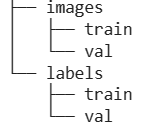

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os
from PIL import Image

In [ ]:
# Set validation and training paths to the dataset
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'
val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'
test_dir_img = 'CloudDataset/test/images'
test_dir_lbl = 'CloudDataset/test/labels'

In [ ]:
os.makedirs('Final_data/images')
os.makedirs('Final_data/labels')


In [ ]:
#set the paths to labels and images directory
label_dir= "Final_data/labels"
image_dir= "Final_data/images"

Copy txt files and jpg files to the folder created

In [ ]:
import os
import shutil
from PIL import Image

# Source directories mapped to their target categories
image_sources = [train_dir_img, val_dir_img, test_dir_img]
label_sources = [train_dir_lbl, val_dir_lbl, test_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".jpg") or file.lower().endswith(".jpeg"):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, file))

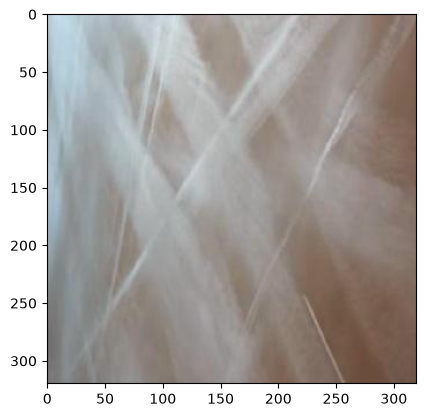

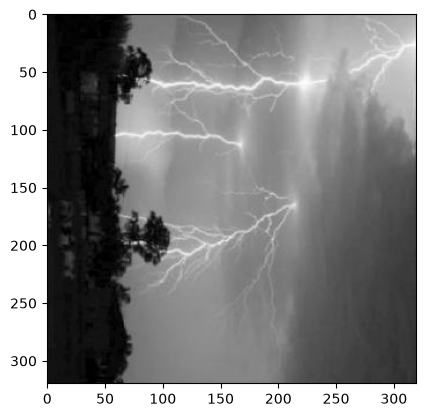

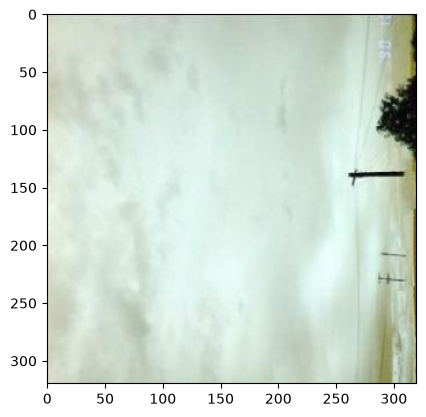

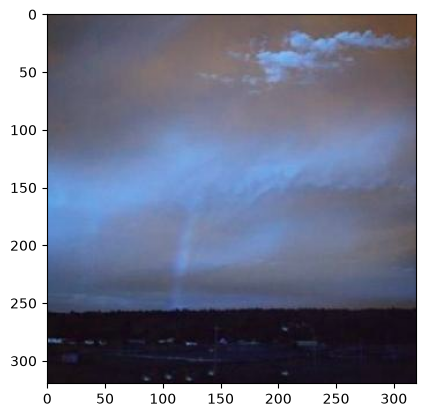

In [ ]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir))):
    img = cv2.imread(os.path.join(image_dir, image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

## Check for missing files

In [ ]:
import glob
import os

# Rename files in image_dir and label_dir replacing '.' with '-'
for folder in [image_dir, label_dir]:
    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)
        if os.path.isfile(filepath):
            name, ext = os.path.splitext(filename)
            if '.' in name:
                new_name = name.replace('.', '-') + ext
                os.rename(filepath, os.path.join(folder, new_name))

#The lists of all the images and labels for train and validation set:
all_images=glob.glob(os.path.join(image_dir,'*.jpg'))
all_labels=glob.glob(os.path.join(label_dir,'*.txt'))


all image number should match all label number

In [ ]:
print(len(all_images), "  =  ", len(all_labels))

11144   =   11144


In [ ]:
from collections import Counter
import os

# Define the path to the images folder
images_path = "Final_data/images"

# Define the mapping between image name prefixes and cloud types
prefix_map = {
    "AC": "Altocumulus",
    "AS": "Altostratus",
    "CB": "Cumulonimbus",
    "CC": "Cirrocumulus",
    "CI": "Cirrus",
    "CS": "Cirrostratus",
    "CT": "Contrails",
    "CU": "Cumulus",
    "NS": "Nimbostratus",
    "SC": "Stratocumulus",
    "ST": "Stratus",
}

# Initialize counters for each cloud prefix
counts = {prefix: 0 for prefix in prefix_map}
unmatched_count = 0

if os.path.exists(images_path):
    # Retrieve all filenames in the directory
    filenames = os.listdir(images_path)

    for filename in filenames:
        # Ensure it is a file rather than a subdirectory
        if os.path.isfile(os.path.join(images_path, filename)):
            filename_upper = filename.upper()
            matched = False

            # Match the prefix against the filename
            for prefix in prefix_map:
                if filename_upper.startswith(prefix):
                    counts[prefix] += 1
                    matched = True
                    break

            if not matched:
                unmatched_count += 1

    # Print the statistical breakdown
    print("=== Cloud Image Count Statistics ===")
    total_matched = 0
    for prefix, name in prefix_map.items():
        cnt = counts[prefix]
        total_matched += cnt
        print(f"[{prefix}] {name:<15}: {cnt:>5} images")

    print("-" * 38)
    print(f"Total Matched Images: {total_matched:>5} images")
    print(f"Unmatched / Other Files: {unmatched_count:>5} files")
    print(f"Total Files in Directory: {len(filenames):>5} files")

else:
    print(f"Directory path not found: {train_images_path}")

=== Cloud Image Count Statistics ===
[AC] Altocumulus    :   953 images
[AS] Altostratus    :   802 images
[CB] Cumulonimbus   :  1013 images
[CC] Cirrocumulus   :  1211 images
[CI] Cirrus         :   603 images
[CS] Cirrostratus   :  1259 images
[CT] Contrails      :   926 images
[CU] Cumulus        :   769 images
[NS] Nimbostratus   :  1234 images
[SC] Stratocumulus  :  1489 images
[ST] Stratus        :   885 images
--------------------------------------
Total Matched Images: 11144 images
Unmatched / Other Files:     0 files
Total Files in Directory: 11144 files


# Model Training

In [ ]:
cloud_labels = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cumulonimbus",
    3: "Cirrocumulus",
    4: "Cirrus",
    5: "Cirrostratus",
    6: "Contrails",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Model Evaluation